# 01 · The model, the bench data and parameter sweeps

**Series: sweeps → sensitivity → calibration → surrogates → optimisation → neural networks**

| # | Notebook | Question it answers |
|---|---|---|
| **01** | **Model, data, sweeps, DoE** | What does my model do when I turn the knobs? How do I sample a parameter space sensibly? |
| 02 | Sensitivity analysis | Which parameters matter, for which output, and which can I identify at all? |
| 03 | Calibration | How do I fit the model to the bench, and how much do I trust the result? |
| 04 | Surrogate models | What if one run takes minutes? When and how do I replace the model by a cheap stand-in? |
| 05 | Design optimisation | How do I use the calibrated model to find designs for future demands, with trade-offs and tolerances? |
| 06 | Bridge to neural networks | Where do neural nets enter this workflow, and where don't they? |

All six notebooks use one small example: a **torsional model of a two-cylinder
motorcycle engine with clutch, gearbox and final drive on a test bench**. It lives in
`driveline.py` and runs in about a millisecond, so we can afford to do everything
"the honest way" first. Notebook 04 then swaps in a slow nonlinear time-domain
version to show what changes when runs become expensive.

The bench data are synthetic: they were produced by `make_bench_data.py` with
parameter values that differ from the nominal ones. Don't open that file yet –
we will try to recover the values in notebook 03 and compare at the end.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc

import driveline as dl
import plotstyle
C = plotstyle.use()
np.set_printoptions(precision=4, suppress=True)

## 1 · The model

Everything is reduced to crankshaft speed, so the driveline is a plain chain of
inertias and torsional springs:

```
 engine torque
      │
  ┌───▼───┐  k_prim  ┌────────┐ k_damper ┌────────┐ k_shaft ┌────────┐  k_cush  ┌────────┐
  │ crank ├──/\/\/───┤ basket ├──/\/\/───┤ gbx in ├──/\/\/──┤ gbx out├──/\/\/───┤ wheel +│
  │ + alt │          │        │ c_damper │  J_gbx │         │sprocket│  c_cush  │  dyno  │
  └───────┘          └────────┘          └────────┘         └────────┘          └────────┘
    DOF 0               DOF 1               DOF 2              DOF 3               DOF 4
```

Equation of motion: $\mathbf{J}\ddot{\boldsymbol\theta} + \mathbf{C}\dot{\boldsymbol\theta} + \mathbf{K}\boldsymbol\theta = \mathbf{T}(t)$.

The engine torque is periodic over 720° crank angle, so it is a sum of **engine
orders** $n = 0.5, 1, 1.5, \dots$ At crank speed $\Omega$ order $n$ excites at
$\omega = n\,\Omega$. For a linear model we can therefore solve each order separately
in the frequency domain,

$$\big(\mathbf{K} + i\omega\mathbf{C} - \omega^2\mathbf{J}\big)\,\hat{\boldsymbol\theta} = \hat{\mathbf{T}}_n(\Omega),$$

which is one small linear solve per (order, speed) point. The outputs we look at
are what two encoders on the bench would deliver after order tracking: the
**speed-fluctuation amplitude** $|i\omega\hat\theta|$ in rad/s at the crank and at the
gearbox input shaft, for five orders over a run-up from 2000 to 10000 rpm.

### 1.1 Excitation from crank geometry

`driveline.py` builds the torque from first principles: a synthetic cylinder
pressure trace (single-zone model with a Wiebe heat release), slider-crank
kinematics, and the oscillating-mass torque, which grows with $\Omega^2$.

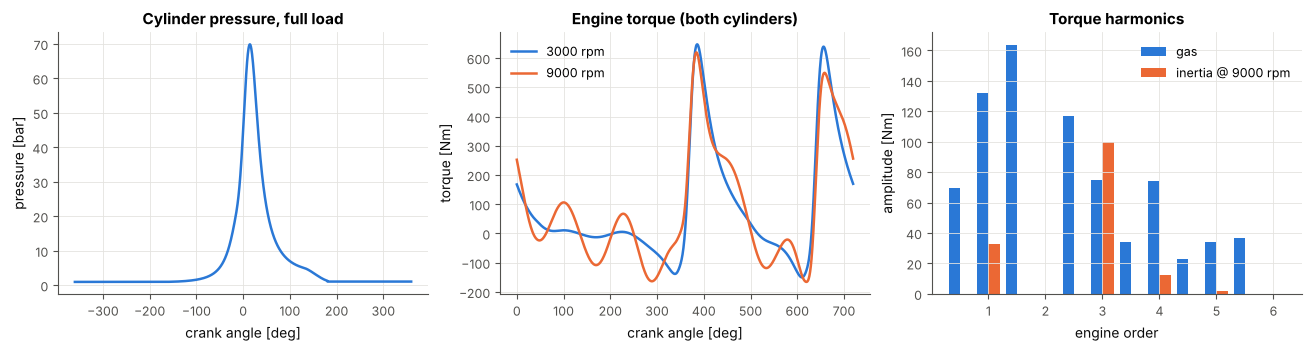

mean indicated torque at full load: 85.9 Nm


In [2]:
eng = dl.Engine()
phi, p = dl.cylinder_pressure(eng, load=1.0)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(np.rad2deg(phi), p / 1e5)
ax[0].set(xlabel="crank angle [deg]", ylabel="pressure [bar]", title="Cylinder pressure, full load")
for rpm, c in ((3000, C[0]), (9000, C[1])):
    ax[1].plot(np.linspace(0, 720, eng.n_grid, endpoint=False),
               dl.torque_time_series(eng, 1.0, rpm), color=c, label=f"{rpm} rpm")
ax[1].set(xlabel="crank angle [deg]", ylabel="torque [Nm]", title="Engine torque (both cylinders)")
ax[1].legend()

all_orders = np.arange(0.5, 6.01, 0.5)
G, I, t_mean = dl.torque_harmonics(eng, 1.0, all_orders)
w = 0.2
ax[2].bar(all_orders - w / 2, np.abs(G), w, label="gas")
ax[2].bar(all_orders + w / 2, np.abs(I) * (9000 * np.pi / 30) ** 2, w, label="inertia @ 9000 rpm")
ax[2].set(xlabel="engine order", ylabel="amplitude [Nm]", title="Torque harmonics")
ax[2].legend()
plt.show()
print(f"mean indicated torque at full load: {t_mean:.1f} Nm")

Two things to notice, both of which matter later:

* **Order 2 is missing.** The two cylinders fire 270° apart, so their order-2
  contributions are 540° out of phase and cancel exactly. That is why the series
  tracks orders 0.5, 1, 1.5, 2.5 and 3. Knowing which orders carry energy tells
  you which resonance crossings the bench can show you at all.
* **Gas torque and inertia torque scale differently** (load vs. speed²). A
  parameter that scales only the gas part (`gas_scale`) therefore leaves a different
  fingerprint than damping, even though both change resonance amplitudes. We will
  use that in notebook 02.

### 1.2 Natural frequencies and the Campbell diagram

natural frequencies [Hz]: [ 13.1  87.8 372.1 578.6]


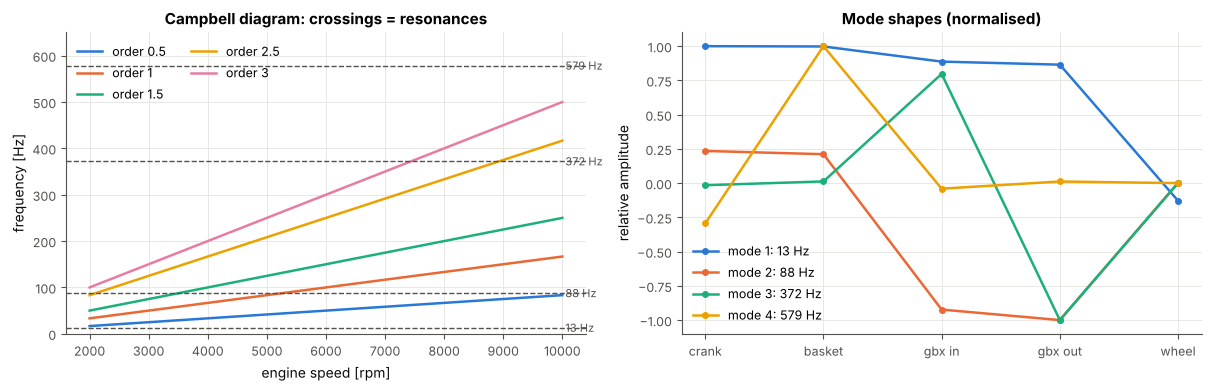

In [3]:
f_n, shapes = dl.natural_frequencies()
print("natural frequencies [Hz]:", f_n.round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n, c in zip(dl.ORDERS, C):
    ax[0].plot(dl.RPM, n * dl.RPM / 60, color=c, label=f"order {n:g}")
for f in f_n:
    ax[0].axhline(f, color=plotstyle.MUTED, lw=1, ls="--")
    ax[0].text(10050, f, f"{f:.0f} Hz", va="center", fontsize=8, color=plotstyle.MUTED)
ax[0].set(xlabel="engine speed [rpm]", ylabel="frequency [Hz]", ylim=(0, 650),
          title="Campbell diagram: crossings = resonances")
ax[0].legend(ncol=2)
labels = ["crank", "basket", "gbx in", "gbx out", "wheel"]
for m in range(4):
    ax[1].plot(labels, shapes[:, m], "o-", label=f"mode {m+1}: {f_n[m]:.0f} Hz")
ax[1].set(title="Mode shapes (normalised)", ylabel="relative amplitude")
ax[1].legend()
plt.show()

Reading the diagram: mode 2 (gearbox side swinging against the crank through
the clutch damper) is crossed by order 1.5 and order 1 inside the run-up – these
will be the dominant peaks. Mode 3 is crossed by orders 2.5 and 3 at the top end.
Mode 1 (whole engine against the wheel through the cush drive) sits far below the
run-up range, and mode 4 (crank against basket through `k_prim`) far above.
**Keep that in mind: the bench cannot tell us much about parameters whose modes it
never excites.** Sensitivity analysis will make this quantitative.

### 1.3 Parameters

Eight parameters are treated as uncertain. Each has a nominal value (think CAD
or data sheet) and bounds, given as multipliers on the nominal value.

In [4]:
print(f"{'name':10s} {'nominal':>10s} {'lower':>10s} {'upper':>10s}  unit")
for n, x0, lo, hi in zip(dl.NAMES, dl.NOMINAL, dl.LOWER, dl.UPPER):
    print(f"{n:10s} {x0:10.4g} {lo:10.4g} {hi:10.4g}  {dl.UNITS[n]}")

t0 = time.perf_counter()
for _ in range(200):
    amp = dl.simulate(dl.NOMINAL)
print(f"\none run-up: {(time.perf_counter() - t0) / 200 * 1e3:.2f} ms, output shape {amp.shape} "
      "(channel, order, rpm)")

name          nominal      lower      upper  unit
k_prim          6e+04      3e+04    1.2e+05  Nm/rad
k_damper         1600        800       3200  Nm/rad
k_shaft          9000       4500    1.8e+04  Nm/rad
k_cush            220        110        440  Nm/rad
c_damper         0.25       0.05       1.25  Nms/rad
c_cush           0.25       0.05       1.25  Nms/rad
J_gbx           0.004     0.0028     0.0056  kgm2
gas_scale           1        0.8       1.25  -

one run-up: 0.33 ms, output shape (2, 5, 81) (channel, order, rpm)


## 2 · The bench data and what "distance to the data" means

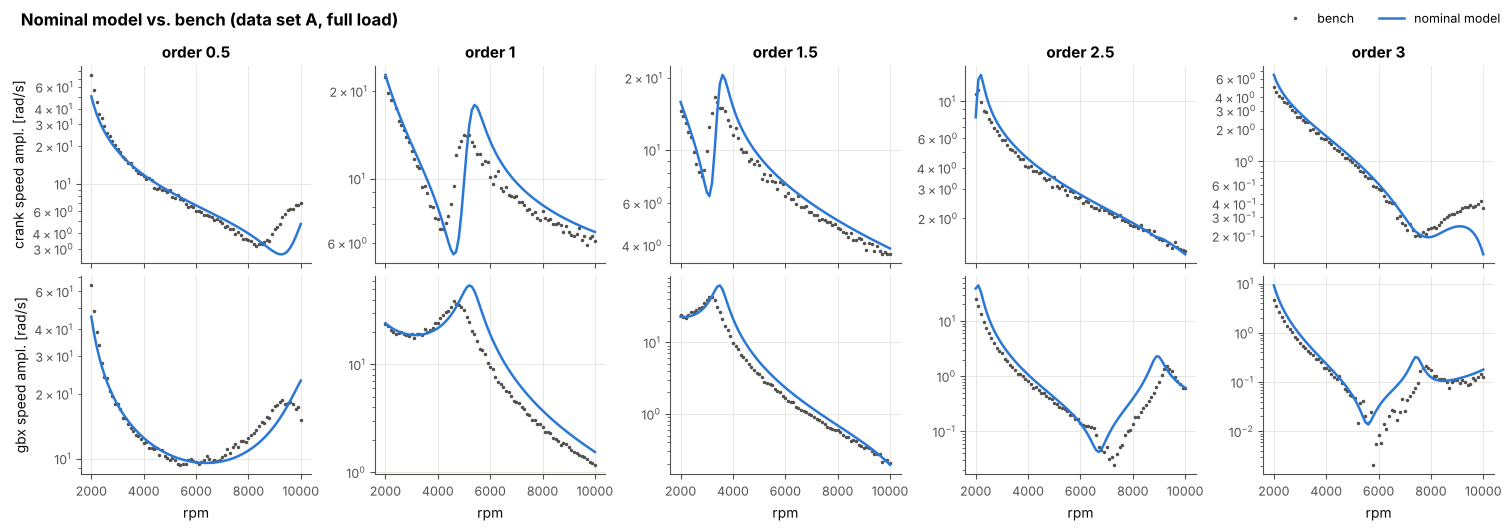

In [5]:
bench = dl.load_bench("A")


def plot_orders(curves, bench=None, title=None, logy=True):
    """curves: list of (label, amp array (2, n_ord, n_rpm), style dict)."""
    fig, axes = plt.subplots(2, len(dl.ORDERS), figsize=(15, 5.2), sharex=True)
    for ch in range(2):
        for o, n in enumerate(dl.ORDERS):
            a = axes[ch, o]
            if bench is not None:
                a.plot(bench["rpm"], bench["amp"][ch, o], ".", color=plotstyle.MUTED, ms=3,
                       label="bench" if (ch, o) == (0, 0) else None)
            for label, amp, st in curves:
                a.plot(dl.RPM, amp[ch, o], label=label if (ch, o) == (0, 0) else None, **st)
            if logy:
                a.set_yscale("log")
            if ch == 0:
                a.set_title(f"order {n:g}")
            if o == 0:
                a.set_ylabel(f"{dl.CHANNELS[ch]} speed ampl. [rad/s]")
            if ch == 1:
                a.set_xlabel("rpm")
    fig.legend(loc="outside upper right", ncol=4)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    return fig, axes


plot_orders([("nominal model", dl.simulate(dl.NOMINAL), dict(color=C[0]))], bench,
            title="Nominal model vs. bench (data set A, full load)")
plt.show()

The nominal model is recognisably the right kind of thing, but resonances sit at
the wrong speeds and the levels are off. To let an algorithm improve this we
need a number that says *how far off*. This choice is not a detail – it decides
what the calibration will care about.

**Residual vector.** For every (channel, order, rpm) point

$$r_i(\boldsymbol\theta) = \ln\big(y_i^{\text{model}}(\boldsymbol\theta) + \epsilon\big) - \ln\big(y_i^{\text{bench}} + \epsilon\big)$$

Why logarithms? The amplitudes span three decades. With plain differences, the
big order-0.5 values at low speed would dominate and a factor-of-two error on a
small order-3 peak would be invisible. In log space an error of 0.1 means "10 %
off", wherever it happens. This is also the statistically right choice when the
measurement scatter is multiplicative (a few percent of the reading), which is
typical for order-tracked amplitudes. The small floor $\epsilon$ = 0.05 rad/s stops
values near the encoder noise floor from dominating.

**Scalar cost.** $J(\boldsymbol\theta) = \sqrt{\operatorname{mean}(r_i^2)}$, the RMS log error.

Keep both in mind. Sweeps and many optimisers only need the scalar $J$. But the
vector $r$ contains far more information (810 numbers instead of one), and the
best calibration methods in notebook 03 exploit exactly that.

In [6]:
r = dl.residuals(dl.NOMINAL, bench)
print(f"residual vector: {r.size} entries,  cost J = {dl.cost(dl.NOMINAL, bench):.3f} "
      f"(≈ {100 * (np.exp(dl.cost(dl.NOMINAL, bench)) - 1):.0f} % typical amplitude error)")

residual vector: 810 entries,  cost J = 0.312 (≈ 37 % typical amplitude error)


## 3 · One-at-a-time sweeps

The most basic tool: vary one parameter, keep the others at nominal, watch the
output. Always look at the **raw curves** first, not only at a cost value – this
is where physical understanding comes from.

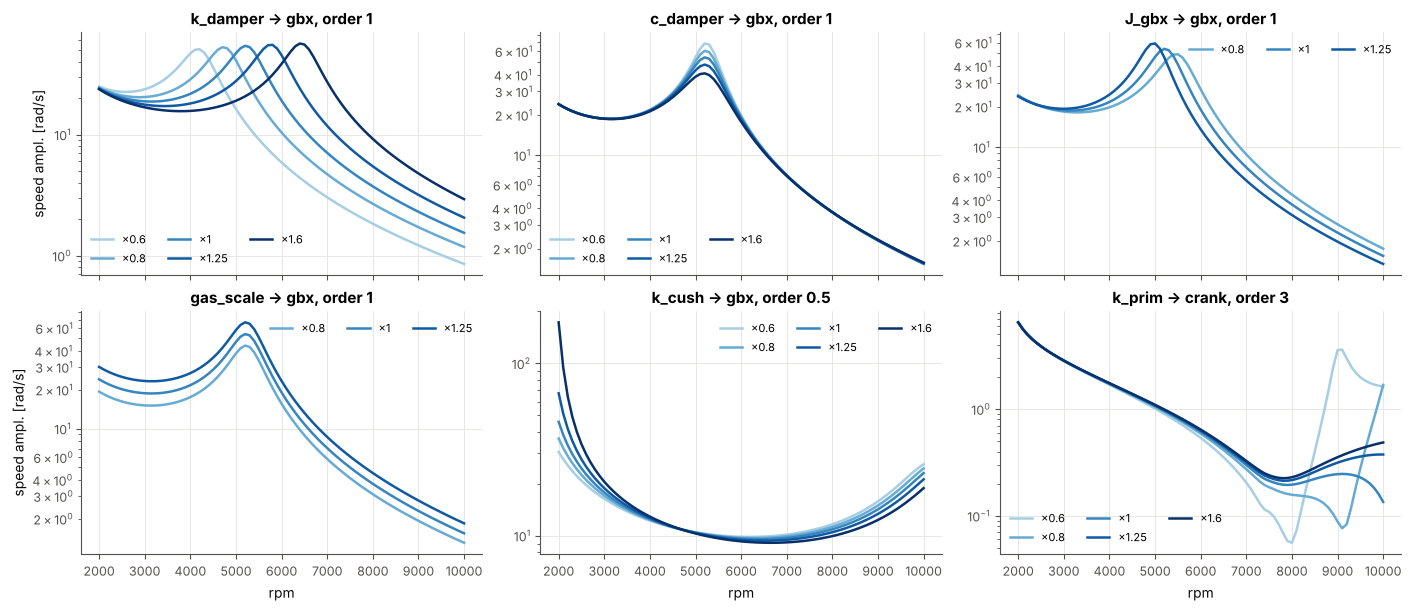

In [7]:
def with_param(name, value, base=dl.NOMINAL):
    x = np.array(base, float)
    x[dl.NAMES.index(name)] = value
    return x


fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
show = [("k_damper", 1, 1), ("c_damper", 1, 1), ("J_gbx", 1, 1),
        ("gas_scale", 1, 1), ("k_cush", 1, 0), ("k_prim", 0, 4)]      # (param, channel, order idx)
mults = [0.6, 0.8, 1.0, 1.25, 1.6]
shades = plt.cm.Blues(np.linspace(0.35, 1.0, len(mults)))
for a, (name, ch, o) in zip(axes.ravel(), show):
    for m, col in zip(mults, shades):
        if not dl.LOWER[dl.NAMES.index(name)] <= m * dl.NOMINAL[dl.NAMES.index(name)] <= dl.UPPER[dl.NAMES.index(name)]:
            continue
        amp = dl.simulate(with_param(name, m * dl.NOMINAL[dl.NAMES.index(name)]))
        a.semilogy(dl.RPM, amp[ch, o], color=col, label=f"×{m:g}")
    a.set_title(f"{name} → {dl.CHANNELS[ch]}, order {dl.ORDERS[o]:g}")
    a.legend(ncol=3, fontsize=8)
for a in axes[1]:
    a.set_xlabel("rpm")
for a in axes[:, 0]:
    a.set_ylabel("speed ampl. [rad/s]")
plt.show()

What the curves say:

* `k_damper` and `J_gbx` both **move** the order-1 resonance – stiffer moves it up,
  heavier moves it down. They do similar things in opposite directions; remember
  that when we talk about identifiability.
* `c_damper` changes the **height** of the peak and nothing away from it.
* `gas_scale` shifts the level **everywhere**, but less where the inertia torque dominates.
* `k_cush` only matters at the very bottom of the run-up, where the tail of
  mode 1 is still visible, and a little at the top where order 0.5 approaches mode 2.
* `k_prim` is **one-sided**: at nominal or stiffer, nothing changes in the measured
  range. Make it much softer and mode 4 drops into the run-up (the peak at
  9000 rpm for ×0.6). The bench can tell us "at least this stiff", not how stiff.

Now the same sweep expressed as cost against the bench data:

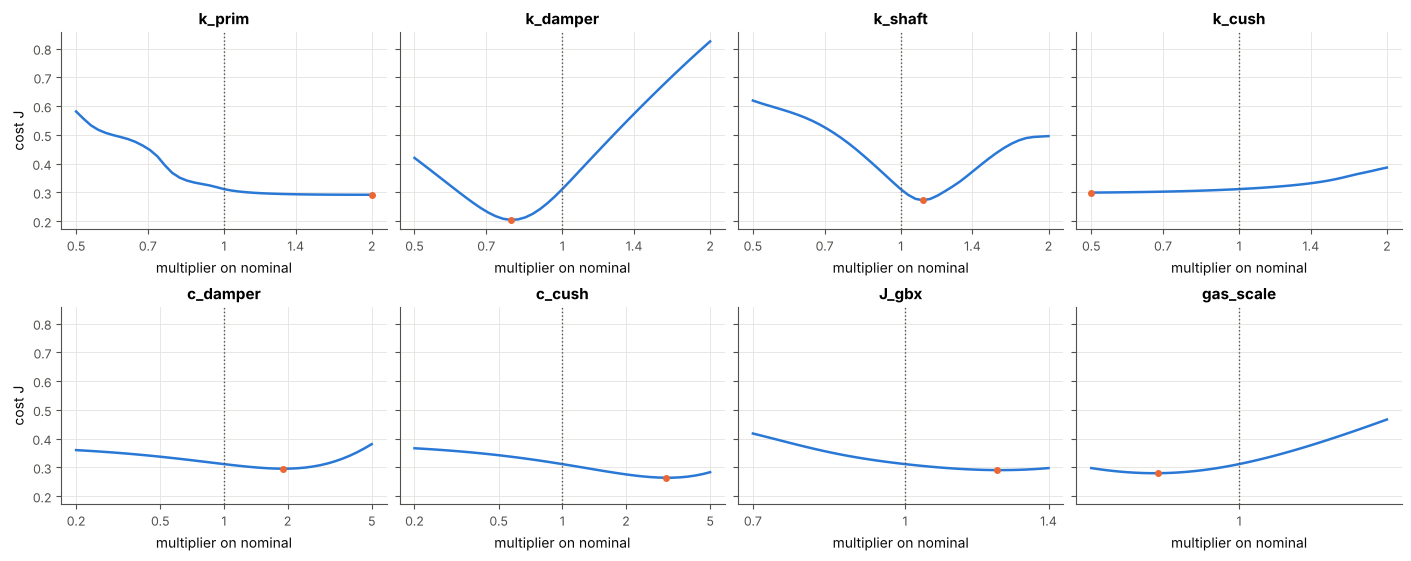

best single-parameter change: k_damper × 0.78  →  J = 0.205


In [8]:
n_sweep = 41
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharey=True)
oat = {}
for a, name in zip(axes.ravel(), dl.NAMES):
    i = dl.NAMES.index(name)
    vals = np.geomspace(dl.LOWER[i], dl.UPPER[i], n_sweep)
    J = np.array([dl.cost(with_param(name, v), bench) for v in vals])
    oat[name] = (vals, J)
    a.plot(vals / dl.NOMINAL[i], J)
    a.axvline(1.0, color=plotstyle.MUTED, lw=1, ls=":")
    a.plot(vals[J.argmin()] / dl.NOMINAL[i], J.min(), "o", color=C[1])
    plotstyle.mult_axis(a)
    a.set_title(name)
    a.set_xlabel("multiplier on nominal")
for a in axes[:, 0]:
    a.set_ylabel("cost J")
plt.show()
n_best = min(oat, key=lambda n: oat[n][1].min())
v_best, J_best = oat[n_best]
print(f"best single-parameter change: {n_best} × {v_best[J_best.argmin()] / dl.NOMINAL[dl.NAMES.index(n_best)]:.2f}"
      f"  →  J = {J_best.min():.3f}")

**Two habits worth adopting from this plot**

1. *Sweep on a logarithmic axis and think in multipliers.* Stiffness, damping and
   inertia are positive scale parameters; "half" and "double" are equally far from
   nominal. All later notebooks work with $\ln\theta$ or with the unit cube
   $u\in[0,1]^8$ that `dl.to_unit` / `dl.from_unit` map to the log-scaled bounds.
   Unscaled parameters (6·10⁴ Nm/rad next to 4·10⁻³ kgm²) are the most common
   reason optimisers and surrogates misbehave.
2. *A flat curve is a finding, not a failure.* `k_cush` hardly changes the cost,
   and `k_prim` only does when it gets soft. Either the parameter does not matter
   for these outputs or the data do not contain the information. Both mean: don't
   expect calibration to pin it down.

**What one-at-a-time sweeps cannot show** is how parameters act *together*. The
minimum of each curve above is only the best value *given that all others stay at
nominal*. With 8 parameters that is a 1-D cut through an 8-D landscape.

## 4 · Two-at-a-time: interactions and valleys

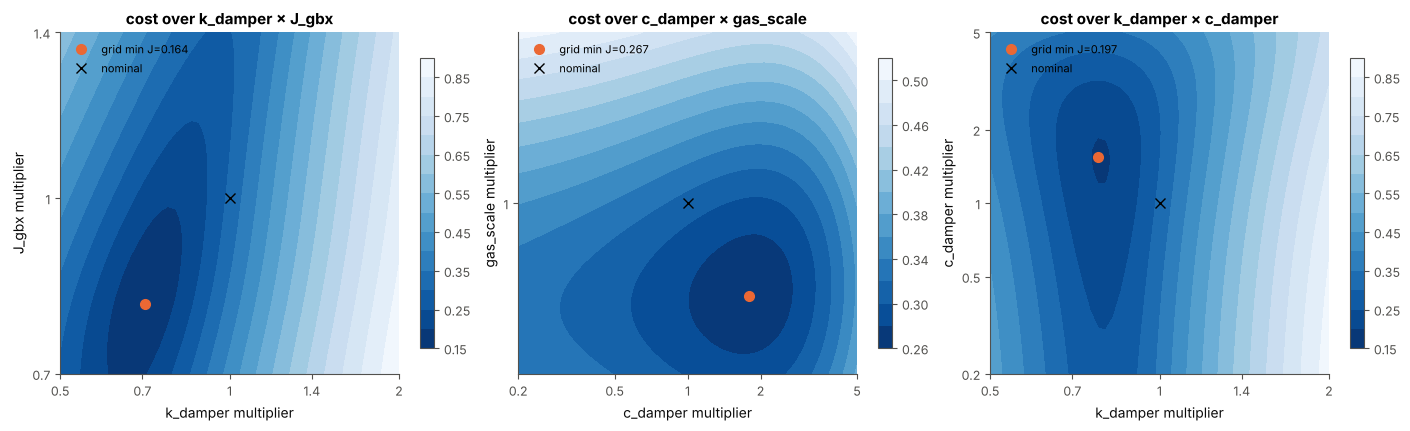

In [9]:
def cost_map(name_a, name_b, n=45):
    ia, ib = dl.NAMES.index(name_a), dl.NAMES.index(name_b)
    va = np.geomspace(dl.LOWER[ia], dl.UPPER[ia], n)
    vb = np.geomspace(dl.LOWER[ib], dl.UPPER[ib], n)
    Jm = np.empty((n, n))
    for i, a_ in enumerate(va):
        for j, b_ in enumerate(vb):
            x = dl.NOMINAL.copy()
            x[ia], x[ib] = a_, b_
            Jm[j, i] = dl.cost(x, bench)
    return va / dl.NOMINAL[ia], vb / dl.NOMINAL[ib], Jm


pairs = [("k_damper", "J_gbx"), ("c_damper", "gas_scale"), ("k_damper", "c_damper")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for a, (na, nb) in zip(axes, pairs):
    va, vb, Jm = cost_map(na, nb)
    cs = a.contourf(va, vb, Jm, levels=14, cmap="Blues_r")
    j, i = np.unravel_index(Jm.argmin(), Jm.shape)
    a.plot(va[i], vb[j], "o", color=C[1], ms=7, label=f"grid min J={Jm.min():.3f}")
    a.plot(1, 1, "x", color="k", ms=7, label="nominal")
    a.set(xlabel=f"{na} multiplier", ylabel=f"{nb} multiplier", title=f"cost over {na} × {nb}")
    plotstyle.mult_axis(a, "x")
    plotstyle.mult_axis(a, "y")
    a.grid(False)
    a.legend(loc="upper left", fontsize=8)
    fig.colorbar(cs, ax=a, shrink=0.85)
plt.show()

* `k_damper × J_gbx`: a tilted, elongated **valley**. Moving along it, stiffness
  and inertia change together so that the resonance frequency ($\propto\sqrt{k/J}$)
  stays roughly where the data want it. The data fix the frequency well; to
  separate $k$ from $J$ they must also contain something that depends on the two
  differently (they do, more weakly – see notebook 02).
* `c_damper × gas_scale`: more excitation with more damping gives a similar peak
  height, which would make a valley. Here the bowl is closed and only slightly
  tilted, because `gas_scale` also acts away from resonance, where damping does
  nothing.
* `k_damper × c_damper`: nearly axis-aligned – location and height of a peak are
  separate pieces of information. These two don't interact much.

Valleys are the geometric picture behind "correlated parameters" and "poor
identifiability". They are also why one-at-a-time *tuning* (fix A, then B, then
A again…) zig-zags slowly.

## 5 · More than two parameters: design of experiments

A full grid with 10 levels in 8 dimensions is $10^8$ runs. Even at 1 ms that is
more than a day; for a model that takes a minute it is 190 years. The way out is
to **sample** the space instead of gridding it. Three standard choices:

| Sampler | Idea | Use it for |
|---|---|---|
| Random (Monte Carlo) | independent uniform draws | baseline; uncertainty propagation |
| Latin hypercube (LHS) | each parameter's range is cut into N slices, every slice is used exactly once | space-filling designs with a fixed, small N (surrogate training) |
| Sobol sequence | deterministic low-discrepancy sequence; points can be **added** later without spoiling uniformity | sensitivity analysis, sequential studies; use N = 2ᵐ |

All are in `scipy.stats.qmc`. The plot shows 64 points in 8-D, projected on two
of the dimensions.

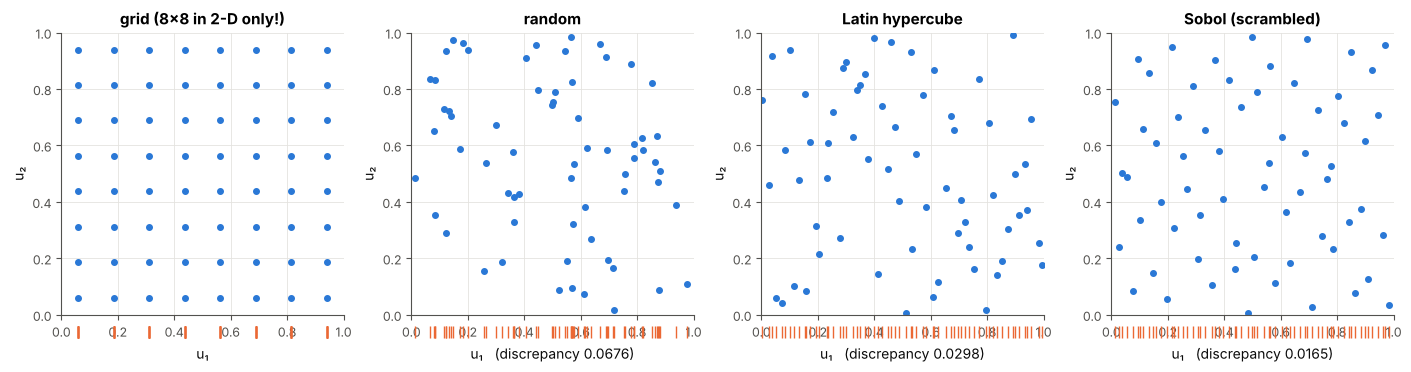

In [10]:
N, D = 64, dl.N_PAR
samples = {
    "grid (8×8 in 2-D only!)": np.stack(np.meshgrid(*[np.linspace(0.06, 0.94, 8)] * 2), -1).reshape(-1, 2),
    "random": np.random.default_rng(0).random((N, D)),
    "Latin hypercube": qmc.LatinHypercube(d=D, seed=0).random(N),
    "Sobol (scrambled)": qmc.Sobol(d=D, seed=0).random(N),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for a, (label, s) in zip(axes, samples.items()):
    a.plot(s[:, 0], s[:, 1], "o", ms=4)
    a.plot(s[:, 0], np.full(len(s), -0.06), "|", color=C[1], ms=8, clip_on=False)
    disc = f"   (discrepancy {qmc.discrepancy(s):.4f})" if s.shape[1] == D else ""
    a.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", title=label, xlabel="u₁" + disc, ylabel="u₂")
plt.show()

The orange ticks are the projection onto one axis. A grid of 64 points tests
only 8 distinct values per parameter (and in 8-D, 64 points would not even give
two levels each). Random sampling leaves holes and clumps. LHS and Sobol give 64
distinct, evenly spread values for *every* parameter – if only two of the eight
parameters turn out to matter, you have still covered those two well. The
"discrepancy" number measures non-uniformity (lower is better).

### 5.1 A first global look: 1024 Sobol samples through the model

1024 runs in 0.4 s;  best J = 0.170  (nominal: 0.312)


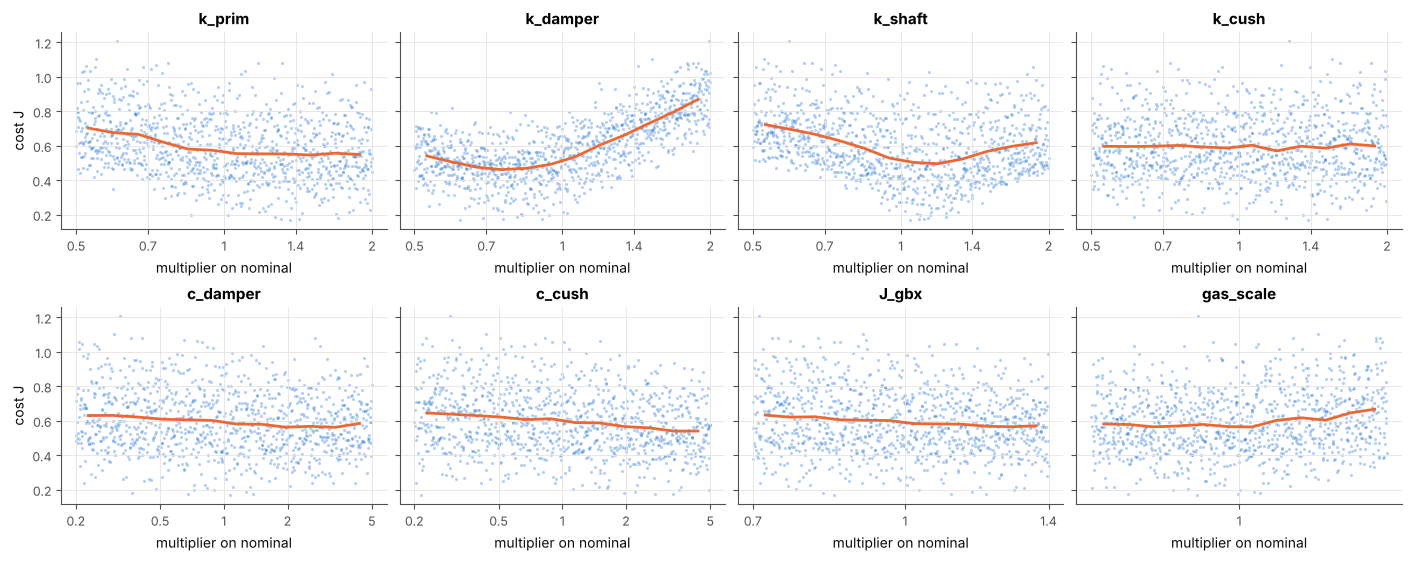

best sample, as multipliers on nominal:
{'k_prim': 1.36, 'k_damper': 0.62, 'k_shaft': 1.04, 'k_cush': 1.38, 'c_damper': 1.06, 'c_cush': 0.21, 'J_gbx': 0.85, 'gas_scale': 0.94}


In [11]:
N = 1024
U = qmc.Sobol(d=D, seed=1).random(N)          # unit cube
X = dl.from_unit(U)                           # physical values, log-scaled between bounds
t0 = time.perf_counter()
J = np.array([dl.cost(x, bench) for x in X])
print(f"{N} runs in {time.perf_counter() - t0:.1f} s;  best J = {J.min():.3f}  "
      f"(nominal: {dl.cost(dl.NOMINAL, bench):.3f})")

fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharey=True)
for a, name in zip(axes.ravel(), dl.NAMES):
    i = dl.NAMES.index(name)
    a.scatter(X[:, i] / dl.NOMINAL[i], J, s=5, alpha=0.35, linewidths=0)
    # binned mean = "main effect" of the parameter
    order = np.argsort(U[:, i])
    bins = np.array_split(order, 12)
    a.plot([np.exp(np.mean(np.log(X[b, i] / dl.NOMINAL[i]))) for b in bins],
           [J[b].mean() for b in bins], color=C[1], lw=2)
    plotstyle.mult_axis(a)
    a.set_title(name)
    a.set_xlabel("multiplier on nominal")
for a in axes[:, 0]:
    a.set_ylabel("cost J")
plt.show()

best = X[J.argmin()]
print("best sample, as multipliers on nominal:")
print({n: round(float(v), 2) for n, v in zip(dl.NAMES, best / dl.NOMINAL)})

Each dot is one run with **all eight** parameters varied at once. The orange
line is the average cost in bins of one parameter – its *main effect*, averaged
over everything else. Parameters with a clear trend (`k_damper`, `k_shaft`, the
soft end of `k_prim`) drive the cost over these wide ranges; a flat line inside a
wide cloud means the parameter matters little on its own. Turning this picture into numbers is exactly what the
variance-based sensitivity indices in notebook 02 do.

Also note: the best of 1024 random-ish samples is clearly better than nominal,
but it is still far from a good fit. **Sampling explores; it does not converge.**
That is the job of the optimisers in notebook 03.

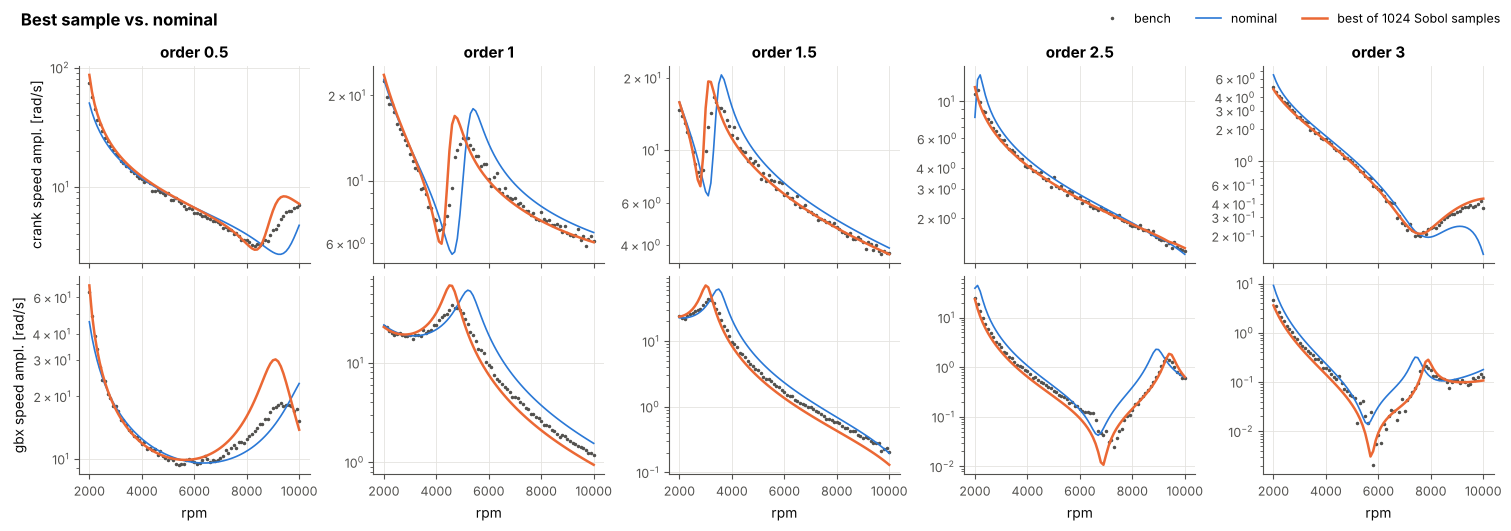

In [12]:
plot_orders([("nominal", dl.simulate(dl.NOMINAL), dict(color=C[0], lw=1.2)),
             ("best of 1024 Sobol samples", dl.simulate(best), dict(color=C[1]))], bench,
            title="Best sample vs. nominal")
plt.show()

## 6 · Doing this with your own models

Everything above only needs a function `outputs = f(parameters)`. For your Dymola
or Python models the recipe is the same; only the wrapper changes:

* **Python models** – wrap the simulation in one function that takes a parameter
  vector and returns the outputs on a fixed grid. Avoid global state.
* **Dymola / Modelica** – export the model as an FMU and drive it with
  [FMPy](https://github.com/CATIA-Systems/FMPy), roughly:

  ```python
  from fmpy import simulate_fmu
  def f(x):
      res = simulate_fmu("Driveline.fmu", start_values=dict(zip(names, x)),
                         stop_time=8.0, output=["crank.w", "gbxIn.w"])
      return order_track(res)          # your post-processing
  ```
  For repeated runs, instantiate the FMU once and reset it between runs; that
  removes most of the overhead.
* **Cache every run** (parameters → outputs, e.g. in an `.npz` or Parquet file).
  Sweeps, sensitivity analysis and surrogate training can all reuse the same
  runs, and a crashed study can resume.
* **Parallelise the outer loop**, not the model: sampling studies are
  embarrassingly parallel (`multiprocessing.Pool.map(f, X)` or `joblib`).
* **Make failed runs explicit.** Return NaN and record the parameters; a solver
  that fails in one corner of the space is information about the model.

## 7 · Summary

* Look at raw output curves before reducing them to a cost.
* The cost definition (here: RMS log-amplitude error) encodes what you care about.
  Keep the residual vector available, not only the scalar.
* Work in multipliers / log-parameters / the unit cube.
* One-at-a-time sweeps are cheap and build intuition, but hide interactions;
  2-D maps reveal valleys = parameter combinations the data cannot separate.
* In more than ~3 dimensions, sample with LHS or Sobol instead of gridding.

### Try it yourself

1. Change `floor` in `dl.residuals` (e.g. 0.5 rad/s) or switch to linear residuals.
   How do the one-at-a-time cost curves change, and which orders dominate?
2. Redo the `k_damper × J_gbx` map using only the gearbox channel, or only order 1.
   Does the valley get longer or shorter?
3. Set `firing=(0.0, 180.0)` in `dl.Engine` and look at the torque harmonics.
   Which orders vanish now?
4. Compare `qmc.discrepancy` of random, LHS and Sobol for N = 16 … 1024.

Next: **02 – Sensitivity analysis.**